# Customer Churn Analysis

## Project Overview

This project aims to analyze customer churn data from a telecom company. The objective is to understand customer behavior, identify factors influencing churn, and gain insights through exploratory data analysis (EDA).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Customer Churn Project\Telco-Customer-Churn.csv")

In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.shape

(7043, 21)

In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

# Customer Churn Analysis

## Initial Observations

- The dataset contains customer information of a telecom company.
- It has 7043 rows and 21 columns.
- It contains both numerical and categorical features.
- No missing values were found.
- No duplicate records were found.
- The dataset is ready for exploratory data analysis (EDA).

# Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the dataset through statistical summaries and visualizations. It helps identify patterns, trends, relationships, and potential issues before building machine learning models.

## 1. Descriptive Statistics

This section provides a statistical summary of the numerical and categorical features in the dataset.

In [15]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


### Observations

- The dataset contains both numerical and categorical features.
- Numerical statistics provide information such as mean, minimum, maximum, and standard deviation.
- Categorical statistics show the number of unique values, most frequent category, and its frequency.

## 2. Univariate Analysis

Univariate analysis examines each variable individually to understand its distribution and characteristics.

### Customer Churn Distribution

In [16]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

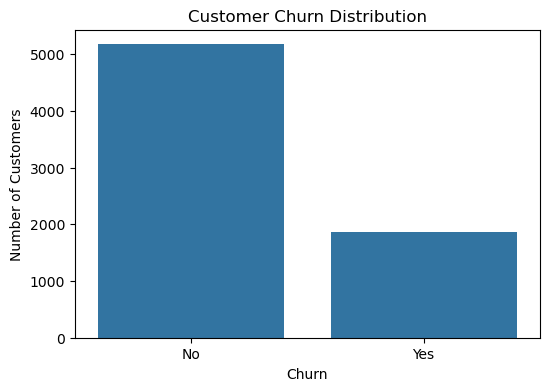

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(x="Churn", data=df)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

### Observation

- Most customers did not churn.
- A smaller proportion of customers churned.
- The dataset is imbalanced, with non-churn customers being the majority.

### Gender Distribution

In [18]:
df["gender"].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

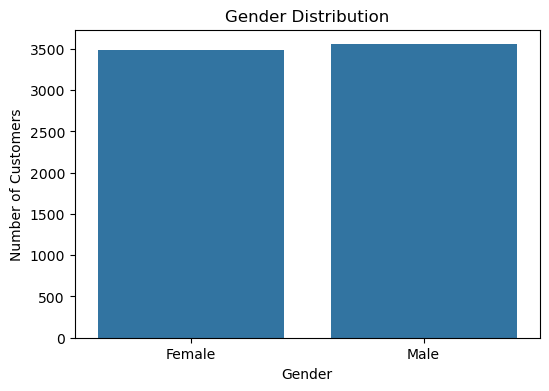

In [19]:
plt.figure(figsize=(6,4))
sns.countplot(x="gender", data=df)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

### Observation

- The dataset contains both male and female customers.
- The number of male and female customers is nearly equal.
- There is no significant gender imbalance in the dataset.

### Contract Type Distribution

In [20]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

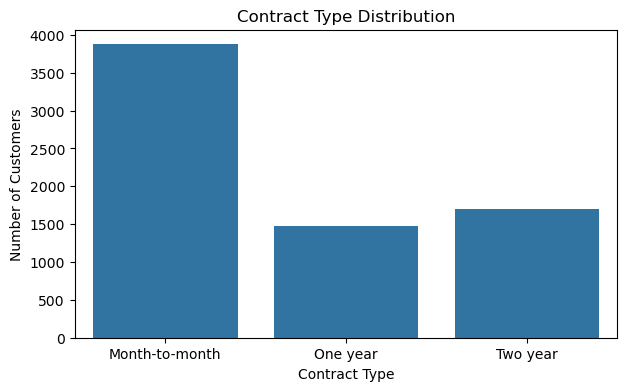

In [21]:
plt.figure(figsize=(7,4))
sns.countplot(x="Contract", data=df)
plt.title("Contract Type Distribution")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

#### Observation

- Month-to-month contracts are the most common among customers.
- One-year and two-year contracts have comparatively fewer customers.
- Customers mostly prefer short-term contracts.

### Internet Service Distribution

In [22]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

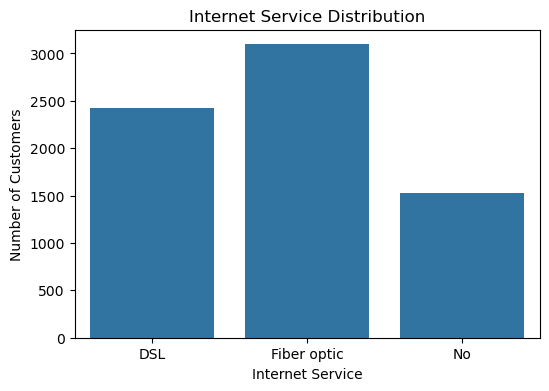

In [23]:
plt.figure(figsize=(6,4))
sns.countplot(x="InternetService", data=df)
plt.title("Internet Service Distribution")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

#### Observation

- Fiber optic and DSL are the primary internet services.
- A smaller group of customers does not use internet services.
- Fiber optic users form a significant portion of the dataset.

### Payment Method Distribution

In [24]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

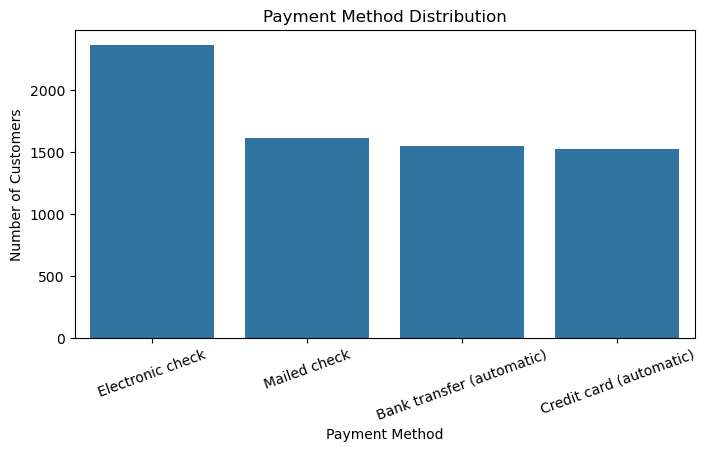

In [25]:
plt.figure(figsize=(8,4))
sns.countplot(x="PaymentMethod", data=df)
plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.show()

#### Observation

- Electronic Check is the most commonly used payment method.
- Mailed Check is used by comparatively fewer customers.
- Bank Transfer and Credit Card payments have similar customer counts.
- Payment method may influence customer churn and will be analyzed later.

### Monthly Charges Distribution

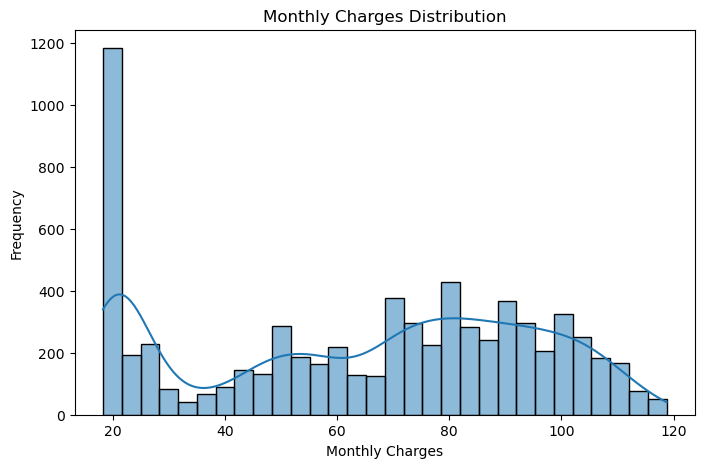

In [26]:
plt.figure(figsize=(8,5))
sns.histplot(df["MonthlyCharges"], bins=30, kde=True)
plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")
plt.show()

#### Observation

- Monthly charges vary across customers.
- A large number of customers fall in the higher monthly charge range.
- A noticeable number of customers also have lower monthly charges.
- The distribution indicates that customers are spread across different pricing plans.

### Tenure Distribution

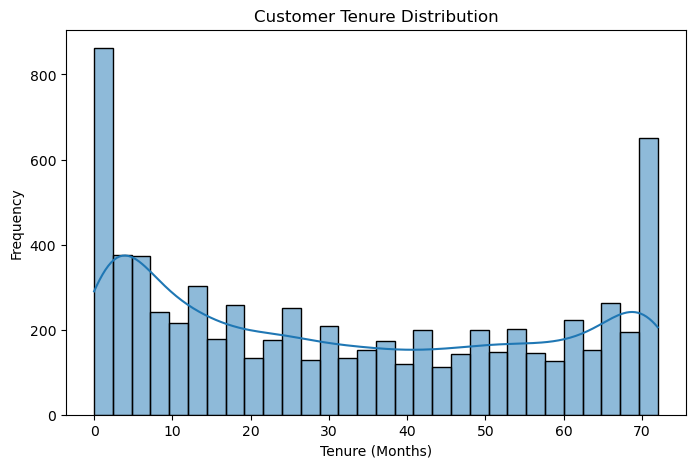

In [5]:
plt.figure(figsize=(8,5))
sns.histplot(df["tenure"], bins=30, kde=True)
plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Frequency")
plt.show()

#### Observation

- Customer tenure varies across the dataset.
- A large number of customers have shorter tenure.
- Many customers have remained with the company for a longer period.
- The distribution indicates the presence of both new and long-term customers.

### Senior Citizen Distribution

In [6]:
df["SeniorCitizen"].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

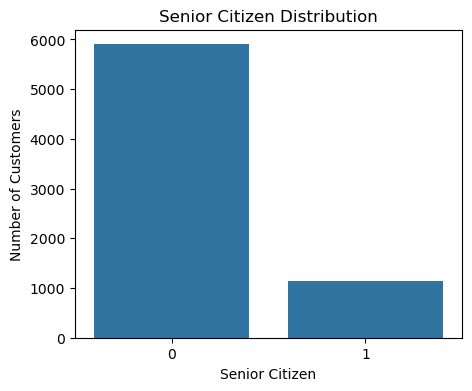

In [7]:
plt.figure(figsize=(5,4))
sns.countplot(x="SeniorCitizen", data=df)
plt.title("Senior Citizen Distribution")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")
plt.show()

#### Observation

- Most customers are not senior citizens.
- Senior citizens make up a smaller proportion of the customer base.
- The dataset is dominated by non-senior customers.

### Partner Distribution

In [8]:
df["Partner"].value_counts()

Partner
No     3641
Yes    3402
Name: count, dtype: int64

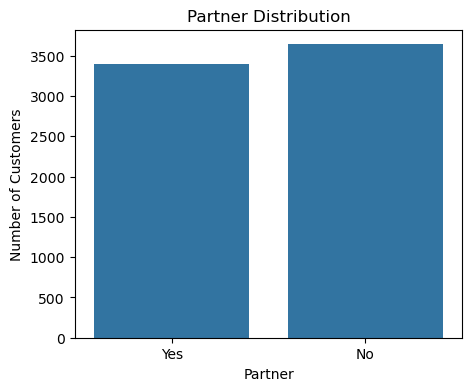

In [9]:
plt.figure(figsize=(5,4))
sns.countplot(x="Partner", data=df)
plt.title("Partner Distribution")
plt.xlabel("Partner")
plt.ylabel("Number of Customers")
plt.show()

#### Observation

- Customers are distributed between those with and without partners.
- The number of customers in both categories is relatively balanced.
- Both groups are well represented in the dataset.

### Dependents Distribution

In [10]:
df["Dependents"].value_counts()

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

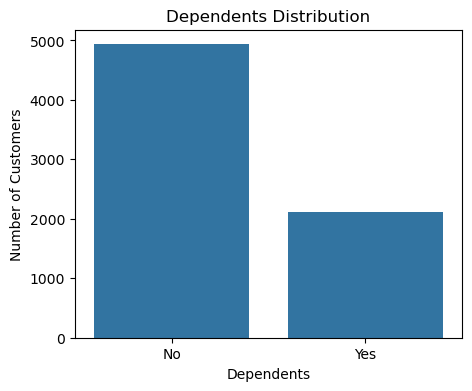

In [11]:
plt.figure(figsize=(5,4))
sns.countplot(x="Dependents", data=df)
plt.title("Dependents Distribution")
plt.xlabel("Dependents")
plt.ylabel("Number of Customers")
plt.show()

#### Observation

- Most customers do not have dependents.
- Customers with dependents represent a smaller portion of the dataset.
- The distribution shows that customers without dependents are more common.

## 4. Bivariate Analysis

Bivariate analysis is performed to examine the relationship between customer churn and different customer attributes. It helps identify the factors that may influence customer retention and customer churn.

### Churn vs Gender

In [21]:
pd.crosstab(df["gender"], df["Churn"], normalize="index") * 100

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


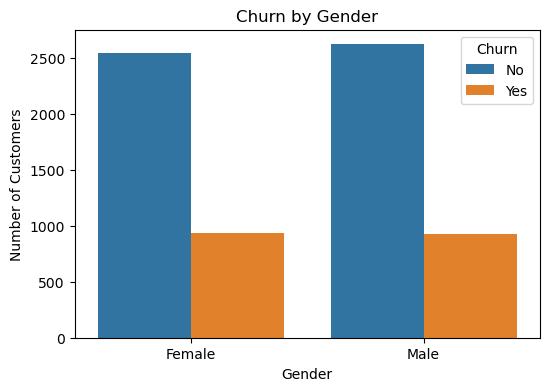

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x="gender", hue="Churn", data=df)
plt.title("Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

#### Observation

- Both male and female customers have similar churn rates.
- Female customers have a churn rate of **26.92%**, while male customers have a churn rate of **26.16%**.
- The difference in churn rates is minimal, indicating that gender does not significantly influence customer churn.

### Churn vs Contract Type

In [18]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


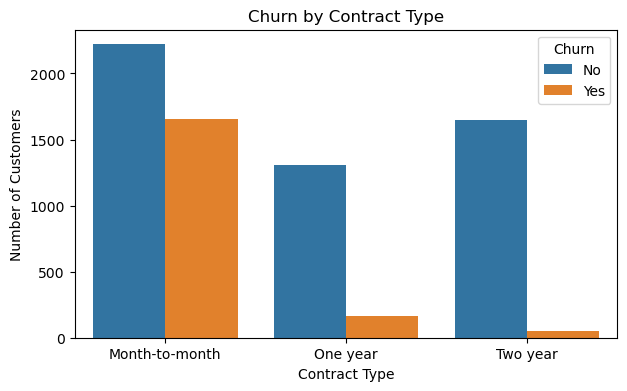

In [13]:
plt.figure(figsize=(7,4))
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

#### Observation

- Customers with month-to-month contracts have the highest churn rate (**42.71%**).
- Customers with one-year contracts have a much lower churn rate (**11.27%**).
- Customers with two-year contracts have the lowest churn rate (**2.83%**).
- Longer contract durations are associated with higher customer retention and lower churn.

### Churn vs Internet Service

In [19]:
pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


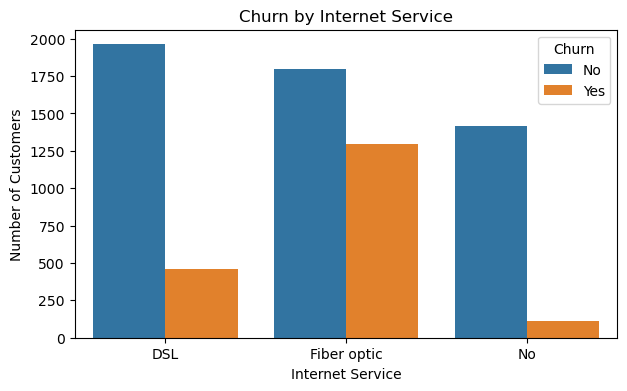

In [14]:
plt.figure(figsize=(7,4))
sns.countplot(x="InternetService", hue="Churn", data=df)
plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

#### Observation

- Customers using **Fiber optic** internet service have the highest churn rate (**41.89%**).
- Customers using **DSL** have a much lower churn rate (**18.96%**).
- Customers with **no internet service** have the lowest churn rate (**7.40%**).
- This suggests that customers using Fiber optic service are more likely to churn than customers using other internet service types.

### Churn vs Payment Method

In [20]:
pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


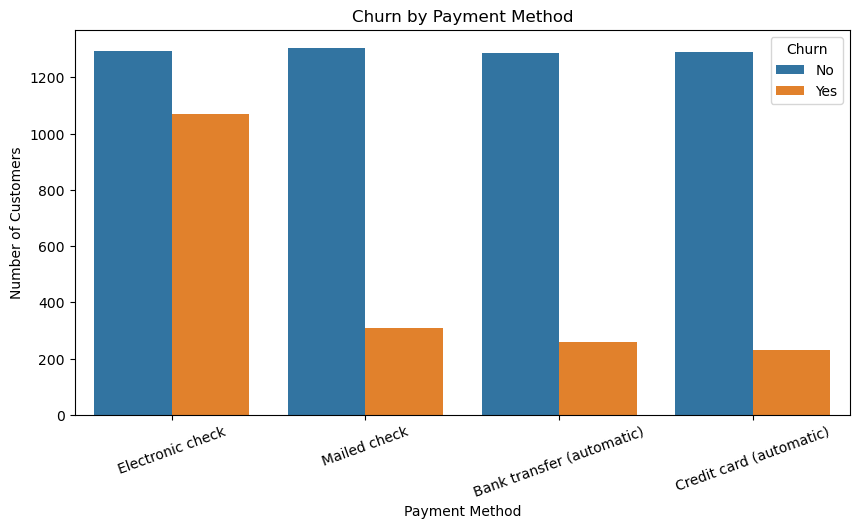

In [15]:
plt.figure(figsize=(10,5))
sns.countplot(x="PaymentMethod", hue="Churn", data=df)
plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.show()

#### Observation

- Customers using **Electronic Check** have the highest churn rate (**45.29%**).
- Customers using **Credit Card (automatic)** have the lowest churn rate (**15.24%**).
- Customers using **Bank Transfer (automatic)** also have a relatively low churn rate (**16.71%**).
- This suggests that customers using automatic payment methods are less likely to churn than customers using Electronic Check.
  

### Churn vs Senior Citizen

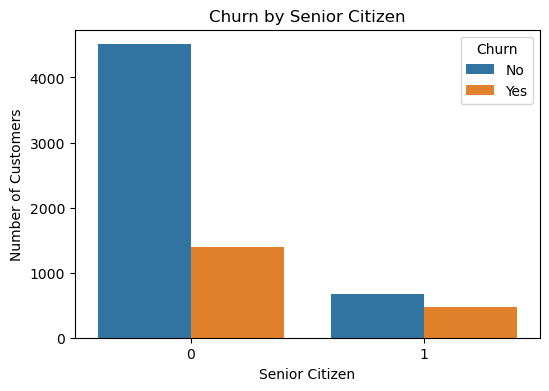

In [16]:
plt.figure(figsize=(6,4))
sns.countplot(x="SeniorCitizen", hue="Churn", data=df)
plt.title("Churn by Senior Citizen")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")
plt.show()

In [17]:
pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize="index") * 100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


#### Observation

- Churn is observed among both senior and non-senior customers.
- Non-senior customers form the majority of the dataset.
- Senior citizens have a higher churn rate (41.68%) compared to non-senior customers (23.61%).
- This suggests that senior citizens are more likely to leave the company's services.

### Churn vs Partner

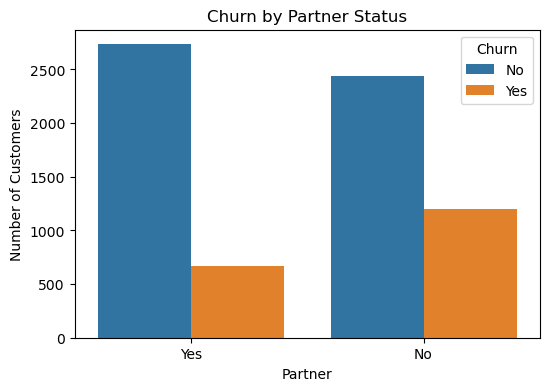

In [22]:
plt.figure(figsize=(6,4))
sns.countplot(x="Partner", hue="Churn", data=df)
plt.title("Churn by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Number of Customers")
plt.show()

In [23]:
pd.crosstab(df["Partner"], df["Churn"], normalize="index") * 100

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


#### Observation

- Customers without a partner have a higher churn rate (**32.96%**).
- Customers with a partner have a lower churn rate (**19.66%**).
- Customers with a partner are more likely to remain with the company.
- This suggests that partner status may influence customer retention.

### Churn vs Dependents

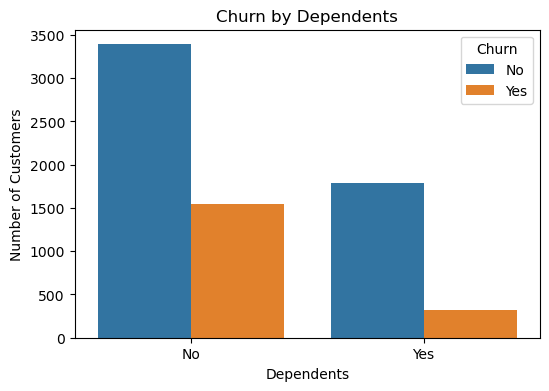

In [24]:
plt.figure(figsize=(6,4))
sns.countplot(x="Dependents", hue="Churn", data=df)
plt.title("Churn by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Number of Customers")
plt.show()

In [25]:
pd.crosstab(df["Dependents"], df["Churn"], normalize="index") * 100

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


#### Observation

- Customers without dependents have a higher churn rate (**31.28%**).
- Customers with dependents have a lower churn rate (**15.45%**).
- Customers with dependents are more likely to remain with the company.
- This suggests that having dependents is associated with lower customer churn.

### Churn vs Monthly Charges

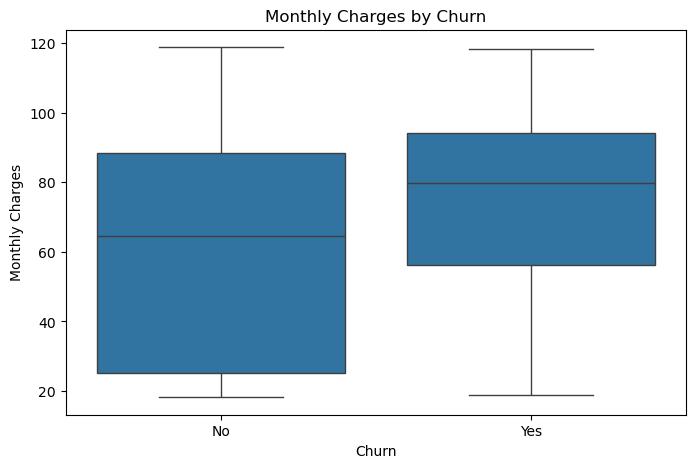

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

#### Observation

- Customers who churned generally have higher monthly charges than customers who did not churn.
- The median monthly charge is higher for churned customers.
- Customers with lower monthly charges are more likely to remain with the company.
- This suggests that higher monthly charges may be associated with an increased likelihood of customer churn.

### Churn vs Tenure

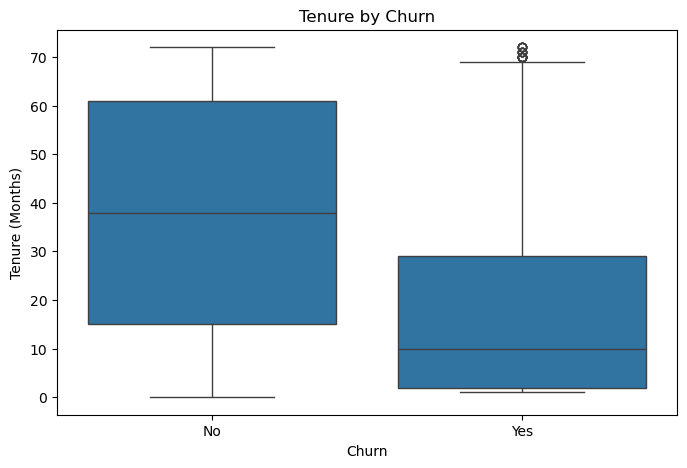

In [27]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

#### Observation

- Customers with lower tenure are more likely to churn.
- Customers with longer tenure tend to remain with the company.
- The median tenure of churned customers is lower than that of non-churned customers.
- This suggests that customer retention improves as the duration of service increases.

## Correlation Analysis

### Correlation Heatmap

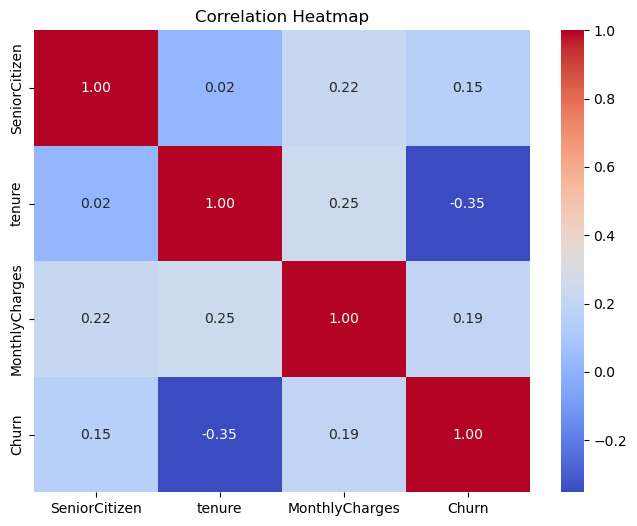

In [28]:
df_corr = df.copy()
df_corr["Churn"] = df_corr["Churn"].map({"No": 0, "Yes": 1})

corr = df_corr.corr(numeric_only=True)

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

#### Observation

- Tenure has a negative correlation with churn, indicating that customers with longer tenure are less likely to leave.
- Monthly charges show a weak positive correlation with churn, suggesting that customers with higher monthly charges are slightly more likely to churn.
- Senior citizen status has a weak positive correlation with churn.
- Overall, tenure appears to be the strongest factor associated with customer churn among the numerical features.

# Key Business Insights

- Most customers stay with the company, while a smaller proportion of customers have churned.
- Customers with month-to-month contracts show the highest churn rate compared to customers with one-year and two-year contracts.
- Customers using Fiber Optic internet service have a higher churn rate than customers using DSL or no internet service.
- Customers using Electronic Check as their payment method have the highest churn rate among all payment methods.
- Customers with shorter tenure are more likely to churn, whereas customers with longer tenure are more likely to remain with the company.
- Higher monthly charges are slightly associated with increased customer churn.
- Customers without partners or dependents exhibit a higher churn rate than those with partners or dependents.
- Senior citizens have a relatively higher churn rate than non-senior customers.

# Conclusion

This analysis explored the factors influencing customer churn in a telecom company using exploratory data analysis (EDA).

The results indicate that customer churn is strongly associated with contract type, tenure, internet service, payment method, and monthly charges. Customers with month-to-month contracts, Fiber Optic internet, electronic check payments, shorter tenure, and higher monthly charges are more likely to leave the company.

These insights can help the company improve customer retention by encouraging long-term contracts, providing targeted support to high-risk customers, and enhancing service quality for customers with higher churn risk.

Overall, the analysis provides valuable business insights that can support data-driven decision-making and customer retention strategies.